# Policy Search Berbasis Target Renstra (Tahap 4, Tabel 15)


## Sel 1. Unggah file .mdl

In [1]:

try:
    from google.colab import files
    _unggah = files.upload()
    MDL_PATH = next(iter(_unggah))          # nama file yang diunggah
except ImportError:
    MDL_PATH = "FIX-SFD-19.mdl"
print("File yang dipakai:", MDL_PATH)

Saving FIX-SFD-19.mdl to FIX-SFD-19.mdl
File yang dipakai: FIX-SFD-19.mdl


## Sel 2. Membaca file `.mdl`

**Inilah bagian Python membaca `.mdl`-mu.** File `.mdl` adalah teks biasa. Fungsi `baca_mdl()` membuka file itu, membuang bagian gambar diagram (setelah tanda `\\\---/// Sketch`), lalu memotong teks menjadi satu entri per variabel. Setiap entri berisi persamaan (misalnya `Produksi Padi = Luas Panen Padi * Produktivitas Padi`). Hasilnya berupa daftar teks persamaan yang kemudian diterjemahkan ke Python di Sel 3.

In [2]:
import re, math, csv, itertools

def norm(s):
    """Samakan penulisan nama variabel: huruf kecil, tanpa tanda kutip, spasi tunggal."""
    return re.sub(r"\s+", " ", s.replace('"', "")).strip().lower()

def baca_mdl(path):
    """>>> BAGIAN INI YANG MEMBACA FILE .mdl <<<
    Mengembalikan daftar teks persamaan, satu per variabel."""
    teks = open(path, encoding="utf-8").read().replace("\r", "")     # 1. buka dan baca isi file
    teks = teks.split("\\\\\\---/// Sketch")[0]                   # 2. buang bagian gambar diagram
    entri, sementara = [], []
    for baris in teks.split("\n"):                                    # 3. satu entri berakhir di baris yang berakhir "|"
        sementara.append(baris)
        if baris.rstrip().endswith("|") and baris.startswith("\t"):
            entri.append("\n".join(sementara)); sementara = []
    hasil = []
    for e in entri:                                                    # 4. ambil bagian persamaan (sebelum satuan dan komentar)
        e = e.replace("{UTF-8}", "")
        if "********" in e:                                            #    lewati judul bagian
            continue
        kepala = re.split(r"\n\t~", e)[0]
        kepala = re.sub(r"\\\n\s*", " ", kepala)                         #    gabungkan baris yang dipotong "\"
        kepala = re.sub(r"\s+", " ", kepala).strip()
        if kepala:
            hasil.append(kepala)
    return hasil

PERSAMAAN = baca_mdl(MDL_PATH)
print(f"Jumlah persamaan yang terbaca dari .mdl: {len(PERSAMAAN)}")
print("\nContoh 5 persamaan pertama:")
for p in PERSAMAAN[:5]:
    print("  -", p[:110])

Jumlah persamaan yang terbaca dari .mdl: 361

Contoh 5 persamaan pertama:
  - Elastisitas Irigasi terhadap RAB=0.05
  - Ketersediaan Bahan Makanan Ubi Kayu=Penyediaan Ubi Kayu*(1-(K Benih Ubi Kayu+K Industri Makanan Ubi Kayu +"K I
  - Elastisitas Harga terhadap Kelangkaan=0.05
  - Elastisitas Produktivitas terhadap NTP=0.5
  - Pengaruh Irigasi terhadap Produktivitas=0.2


## Sel 3. Menerjemahkan persamaan ke Python dan menjalankan simulasi

Sel ini mengubah setiap persamaan dari Sel 2 menjadi kode Python (kelas `Model`) dan menjalankannya dengan metode Euler, langkah 1 tahun, 2018–2035, sama seperti Vensim. Fungsi yang didukung: `IF THEN ELSE`, `WITH LOOKUP`, `MAX`, `MIN`, `SMOOTHI`, `DELAY1I`, `INTEG`, dan tabel lookup. Akan error jika pakai model lain

In [3]:
class Model:
    def __init__(self, persamaan):
        self.vars, self.lookups = {}, {}
        for h in persamaan:                                   # <- memakai hasil baca_mdl() di Sel 2
            if re.match(r"^[^=]*\(\s*\[\(", h):               # tabel lookup berdiri sendiri
                nm = norm(h.split("(")[0])
                isi = h[h.index("(") + 1:].split("]", 1)[1]
                self.lookups[nm] = [(float(a), float(b)) for a, b in
                                    re.findall(r"\(\s*(-?[\d.eE+-]+)\s*,\s*(-?[\d.eE+-]+)\s*\)", isi)]
            elif "=" in h:
                kiri, kanan = h.split("=", 1)
                self.vars[norm(kiri)] = kanan.strip()
        self.names = list(self.vars)
        self.idx = {n: i for i, n in enumerate(self.names)}
        semua = sorted(list(self.idx) + list(self.lookups), key=len, reverse=True)
        self.NAME_RE = re.compile(r"(?<![\w.])(" + "|".join(re.escape(n) for n in semua) + r")(?![\w])", re.I)
        self.FUNC_RE = re.compile(r"(?<![\w])(if then else|with lookup|smoothi|delay1i|integ|max|min|exp|ln|abs|sqrt)\s*\(", re.I)
        self.SM, self.STOCK, self.CODE = [], {}, {}
        for n, r in self.vars.items():
            if re.match(r"\s*integ\s*\(", r, re.I):
                a = self._args(r[r.index("(") + 1:r.rindex(")")])
                self.STOCK[n] = (self._c(self._tr(a[1])), self._c(self._tr(a[0])))   # (nilai awal, laju)
            else:
                self.CODE[n] = self._c(self._tr(r))
        self.SMC = [tuple(self._c(x) for x in s) for s in self.SM]

    @staticmethod
    def _c(s): return compile(s.strip(), "<mdl>", "eval")

    @staticmethod
    def _args(s):
        a, d, cur = [], 0, ""
        for ch in s:
            if ch in "([": d += 1
            if ch in ")]": d -= 1
            if ch == "," and d == 0: a.append(cur); cur = ""
            else: cur += ch
        a.append(cur); return a

    def _plain(self, e):
        def rep(m):
            n = m.group(1).lower()
            return "LKF(%r)" % n if n in self.lookups else "V(%d)" % self.idx[n]
        e = self.NAME_RE.sub(rep, e)
        e = re.sub(r"(?<![\w.])time(?![\w])", "TT", e, flags=re.I)
        e = e.replace("^", "**")
        return re.sub(r"(?<![<>=!])=(?!=)", "==", e)

    def _tr(self, e):
        e = e.replace('"', ""); out = ""; i = 0
        while i < len(e):
            m = self.FUNC_RE.search(e, i)
            if not m: out += self._plain(e[i:]); break
            out += self._plain(e[i:m.start()])
            j, d = m.end(), 1
            while d:
                d += (e[j] == "(") - (e[j] == ")"); j += 1
            inner, f = e[m.end():j - 1], m.group(1).lower()
            if f == "with lookup":
                a = self._args(inner)
                pts = re.findall(r"\(\s*(-?[\d.eE+-]+)\s*,\s*(-?[\d.eE+-]+)\s*\)", a[1].split("]", 1)[1])
                out += "LKP(%s,%r)" % (self._tr(a[0]), [(float(p), float(q)) for p, q in pts])
            else:
                a = [self._tr(x) for x in self._args(inner)]
                if f == "if then else": out += "ITE(lambda:(%s),lambda:(%s),lambda:(%s))" % tuple(a)
                elif f in ("smoothi", "delay1i"): self.SM.append(tuple(a)); out += "SS(%d)" % (len(self.SM) - 1)
                elif f == "integ": out += "(0)"
                else: out += "%s(%s)" % ({"max": "max", "min": "min", "exp": "math.exp", "ln": "math.log",
                                          "abs": "abs", "sqrt": "math.sqrt"}[f], ",".join(a))
            i = j
        return out

    def run(self, over=None, t0=2018, t1=2035, dt=1.0):
        """Jalankan simulasi. over = {nama variabel: nilai} untuk mengubah variabel keputusan.
        Hasil: {tahun: {nama variabel: nilai}}"""
        over = {norm(k): v for k, v in (over or {}).items()}
        for k in over:
            if k not in self.vars:
                raise KeyError(f"Variabel '{k}' tidak ada di .mdl. Cek ejaan nama variabel keputusan.")
        st, sm, hasil = {}, [None] * len(self.SMC), {}

        def ITE(c, a, b): return a() if c() else b()
        def LKP(x, p):
            if x <= p[0][0]: return p[0][1]
            if x >= p[-1][0]: return p[-1][1]
            for (x0, y0), (x1, y1) in zip(p, p[1:]):
                if x0 <= x <= x1: return y1 if x1 == x0 else y0 + (y1 - y0) * (x - x0) / (x1 - x0)

        def buat(TT):
            cache = {}
            def V(i):
                if i not in cache:
                    n = self.names[i]
                    cache[i] = over[n] if n in over else st[n] if n in self.STOCK else eval(self.CODE[n], env)
                return cache[i]
            env = dict(V=V, SS=lambda k: sm[k], TT=TT, LKP=LKP, ITE=ITE, math=math,
                       LKF=lambda n: (lambda x: LKP(x, self.lookups[n])))
            return env, cache

        env, cache = buat(t0)
        for n, (ini, _) in self.STOCK.items():
            st[n] = over[n] if n in over else eval(ini, env)
        cache.clear()
        for k, (ini, T, init) in enumerate(self.SMC): sm[k] = eval(init, env)
        t = t0
        while t <= t1 + 1e-9:
            env, cache = buat(t)
            for n in self.names:
                try: env["V"](self.idx[n])
                except ZeroDivisionError: cache[self.idx[n]] = float("nan")
            hasil[int(t)] = {self.names[i]: v for i, v in cache.items()}
            baru = {n: st[n] + dt * eval(self.STOCK[n][1], env) for n in self.STOCK if n not in over}
            sm_baru = [sm[k] + dt * (eval(a, env) - sm[k]) / eval(T, env) for k, (a, T, _) in enumerate(self.SMC)]
            st.update(baru); sm[:] = sm_baru; t += dt
        return hasil

model = Model(PERSAMAAN)
print(f"Model siap: {len(model.names)} variabel, {len(model.STOCK)} stok (INTEG), {len(model.SMC)} smoothing/delay.")

Model siap: 360 variabel, 11 stok (INTEG), 14 smoothing/delay.


## Sel 4. Parameter target dan tingkat intervensi

 (huruf besar-kecil tidak berpengaruh).

In [4]:
# Variabel keputusan dan tingkat intervensinya (Tabel 14): nol, rendah, sedang, tinggi
LEVEL = {
    "% LP2B":                       [0, 0.25, 0.50, 1.00],
    "% Kenaikan Subsidi":           [0, 0.10, 0.20, 0.30],
    "Persentase Perubahan Irigasi": [0, 0.01, 0.02, 0.03],
    "% Penambahan RAB":             [0, 0.10, 0.20, 0.30],
}
KOMODITAS = ["padi", "jagung", "kedelai", "kacang tanah", "kacang hijau", "ubi kayu", "ubi jalar"]

# Target Renstra: produksi tanaman pangan + hortikultura 13.774.058 ton (2024) -> 14.292.209 ton (2030)
TAHUN_DASAR, TAHUN_TARGET = 2024, 2030
KENAIKAN_TARGET = 14292209 / 13774058 - 1          # +3,76%

# Aturan memilih T1-T3 dari kombinasi yang memenuhi target:
#   "sedikit_kebijakan" : kebijakan aktif paling sedikit, lalu total level terendah
#   "rab_terendah"      : anggaran (RAB) terendah, lalu kebijakan aktif paling sedikit
ATURAN = "sedikit_kebijakan"
JUMLAH_SKENARIO_TARGET = 3

# Skenario terbaik S1-S3 (Tabel 63) untuk pembanding: (LP2B, Subsidi, Irigasi, RAB)
SKENARIO_TERBAIK = {"S1": (1, 0.3, 0.03, 0.3), "S2": (1, 0, 0.03, 0.3), "S3": (0, 0.3, 0.03, 0.3)}

def total_produksi(d):
    return sum(d["produksi padi" if k == "padi" else "produksi " + k] for k in KOMODITAS)

## Sel 5. Cek baseline


In [5]:
KOLOM = list(LEVEL)
base = model.run()
padi24, tot24 = base[TAHUN_DASAR]["produksi padi"], total_produksi(base[TAHUN_DASAR])
TARGET_TOTAL = tot24 * (1 + KENAIKAN_TARGET)
TARGET_PADI = padi24 * (1 + KENAIKAN_TARGET)
print(f"Produksi padi {TAHUN_DASAR} (baseline): {padi24:,.2f} ton")
print(f"Produksi padi {TAHUN_TARGET} (baseline): {base[TAHUN_TARGET]['produksi padi']:,.2f} ton")
print(f"\nTotal produksi 7 komoditas {TAHUN_DASAR}: {tot24:,.0f} ton")
print(f"Target Goal A (total 7 komoditas {TAHUN_TARGET}) >= {TARGET_TOTAL:,.0f} ton")
print(f"Target Goal B (padi saja {TAHUN_TARGET})        >= {TARGET_PADI:,.0f} ton")

Produksi padi 2024 (baseline): 8,923,146.91 ton
Produksi padi 2030 (baseline): 8,898,347.61 ton

Total produksi 7 komoditas 2024: 11,283,294 ton
Target Goal A (total 7 komoditas 2030) >= 11,707,748 ton
Target Goal B (padi saja 2030)        >= 9,258,817 ton


## Sel 6. Menjalankan 256 simulasi
Setiap kombinasi dari 4 tingkat × 4 kebijakan dijalankan, lalu dicek apakah memenuhi target.

In [6]:
import pandas as pd
baris = []
for kombinasi in itertools.product(*LEVEL.values()):
    d = model.run(dict(zip(KOLOM, kombinasi)))[TAHUN_TARGET]
    baris.append(dict(zip(KOLOM, kombinasi),
                      padi_2030=d["produksi padi"], total_2030=total_produksi(d),
                      ncpr_2030=d["ncpr"], ntp_2030=d["ntp tanaman pangan"]))
hasil = pd.DataFrame(baris)
hasil["goal_A"] = hasil["total_2030"] >= TARGET_TOTAL
hasil["goal_B"] = hasil["padi_2030"] >= TARGET_PADI
hasil["kebijakan_aktif"] = (hasil[KOLOM] > 0).sum(axis=1)
hasil["total_level"] = sum(hasil[k] / max(LEVEL[k]) for k in KOLOM).round(3)
hasil["kenaikan_thd_2024_%"] = ((hasil["total_2030"] / tot24 - 1) * 100).round(2)
hasil["margin_thd_target_%"] = ((hasil["total_2030"] / TARGET_TOTAL - 1) * 100).round(2)
print(f"{len(hasil)} simulasi | memenuhi Goal A (total): {hasil.goal_A.sum()} | memenuhi Goal B (padi): {hasil.goal_B.sum()}")

256 simulasi | memenuhi Goal A (total): 67 | memenuhi Goal B (padi): 2


## Sel 7. Tabel 65: skenario berbasis target (T1–T3)

In [7]:
urut = {"sedikit_kebijakan": ["kebijakan_aktif", "total_level"],
        "rab_terendah": ["% Penambahan RAB", "kebijakan_aktif", "total_level"]}[ATURAN]
lolos = hasil[hasil.goal_A].sort_values(urut).reset_index(drop=True)
T = lolos.head(JUMLAH_SKENARIO_TARGET).copy()
T.index = [f"T{i}" for i in range(1, len(T) + 1)]
tabel65 = T[KOLOM + ["total_2030", "kenaikan_thd_2024_%", "margin_thd_target_%"]].copy()
tabel65["total_2030"] = (tabel65["total_2030"] / 1e6).round(3)
tabel65.columns = ["LP2B", "Subsidi pupuk", "Irigasi (per tahun)", "Belanja pemerintah",
                   "Produksi total 2030 (juta ton)", "Kenaikan thd 2024 (%)", "Margin thd target (%)"]
print(f"Target: >= {TARGET_TOTAL/1e6:.3f} juta ton (kenaikan {KENAIKAN_TARGET*100:.2f}%) | aturan pemilihan: {ATURAN}")
display(tabel65)
SKENARIO_TARGET = {k: tuple(T.loc[k, KOLOM]) for k in T.index}

Target: >= 11.708 juta ton (kenaikan 3.76%) | aturan pemilihan: sedikit_kebijakan


,LP2B,Subsidi pupuk,Irigasi (per tahun),Belanja pemerintah,Produksi total 2030 (juta ton),Kenaikan thd 2024 (%),Margin thd target (%)
T1,0.00,0.0,0.03,0.2,11.731,3.96,0.20
T2,0.00,0.0,0.03,0.3,11.768,4.29,0.51
T3,0.25,0.0,0.03,0.1,11.713,3.81,0.04


## Sel 8. Tabel 66: perubahan variabel keluaran terhadap baseline
Ubah `TAHUN_TABEL` ke 2035 kalau ingin seragam dengan Tabel 62–64.

In [8]:
TAHUN_TABEL = 2030

def indikator(d):
    energi = d["kontribusi energi padi-padian"] + d["kontribusi energi kacang-kacangan"] + d["kontribusi energi umbi-umbian"]
    pph = d["skor pph padi-padian"] + d["skor pph kacang-kacangan"] + d["skor pph umbi-umbian"]
    return {"Luas lahan": d["luas lahan pertanian"], "Luas irigasi": d["luas sawah irigasi"],
            "Produksi padi": d["produksi padi"], "Penyediaan beras": d["penyediaan beras"],
            "Energi": energi, "Skor PPH": pph, "NCPR": d["ncpr"], "NTP": d["ntp tanaman pangan"],
            "PDRB": d["pdrb pertanian tanaman pangan"], "Produksi total": total_produksi(d)}

semua_skenario = {"Baseline": (0, 0, 0, 0), **SKENARIO_TERBAIK, **SKENARIO_TARGET}
nilai = {nama: indikator(model.run(dict(zip(KOLOM, c)))[TAHUN_TABEL]) for nama, c in semua_skenario.items()}
b = nilai["Baseline"]
tabel66 = pd.DataFrame({n: {k: (v[k] / b[k] - 1) * 100 for k in v} for n, v in nilai.items() if n != "Baseline"}).T.round(2)
print(f"Perubahan terhadap baseline, tahun {TAHUN_TABEL} (%)")
display(tabel66)
print("\nNilai baseline:"); display(pd.Series(b).round(4).to_frame("Baseline"))

Perubahan terhadap baseline, tahun 2030 (%)


,Luas lahan,Luas irigasi,Produksi padi,Penyediaan beras,Energi,Skor PPH,NCPR,NTP,PDRB,Produksi total
S1,0.43,18.18,4.15,4.13,3.20,2.47,-3.32,0.31,3.58,3.36
S2,0.43,18.18,3.99,3.97,3.06,2.36,-3.17,-0.02,3.43,3.20
S3,0.00,18.18,3.72,3.71,2.82,2.17,-2.92,0.32,3.17,2.93
T1,0.00,16.12,3.15,3.14,2.36,1.82,-2.45,-0.02,2.66,2.45
T2,0.00,18.18,3.57,3.55,2.67,2.06,-2.77,-0.01,3.02,2.77
T3,0.17,14.06,2.91,2.89,2.20,1.70,-2.30,-0.05,2.48,2.29



Nilai baseline:


,Baseline
Luas lahan,1.601014e+06
Luas irigasi,7.236360e+05
Produksi padi,8.898348e+06
Penyediaan beras,5.288552e+06
Energi,1.213535e+03
Skor PPH,3.278060e+01
NCPR,9.541000e-01
NTP,9.902680e+01
PDRB,4.597326e+13
Produksi total,1.145012e+07


## Sel 9. Grafik produksi total terhadap target

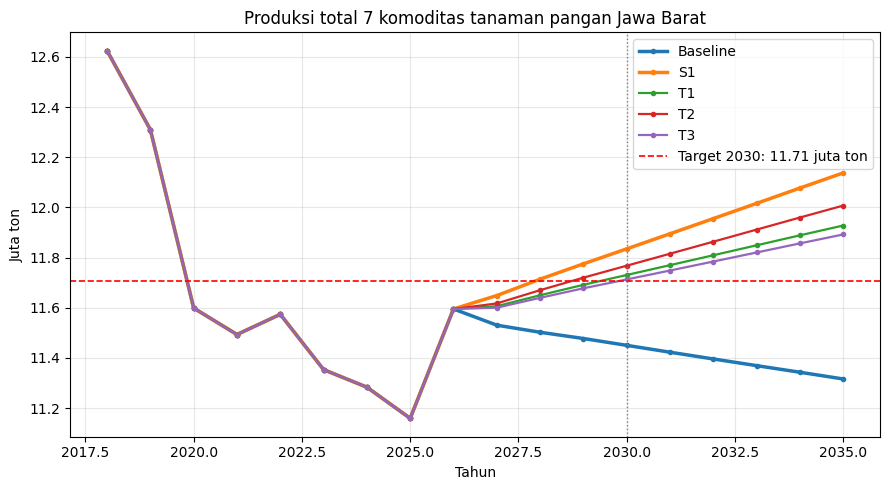

In [9]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
for nama in ["Baseline", "S1"] + list(SKENARIO_TARGET):
    r = model.run(dict(zip(KOLOM, semua_skenario[nama])))
    plt.plot(list(r), [total_produksi(r[y]) / 1e6 for y in r], marker="o", ms=3,
             lw=2.5 if nama in ("Baseline", "S1") else 1.6, label=nama)
plt.axhline(TARGET_TOTAL / 1e6, color="red", ls="--", lw=1.2, label=f"Target {TAHUN_TARGET}: {TARGET_TOTAL/1e6:.2f} juta ton")
plt.axvline(TAHUN_TARGET, color="grey", ls=":", lw=1)
plt.title("Produksi total 7 komoditas tanaman pangan Jawa Barat")
plt.xlabel("Tahun"); plt.ylabel("Juta ton"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Sel 10. Menyimpan hasil

In [10]:
hasil.to_csv("hasil_256_simulasi.csv", index=False)
lolos.to_csv("hasil_skenario_target.csv", index=False)
with pd.ExcelWriter("hasil_policy_search.xlsx") as w:
    tabel65.to_excel(w, sheet_name="Tabel 65 (T1-T3)")
    tabel66.to_excel(w, sheet_name=f"Tabel 66 ({TAHUN_TABEL})")
    lolos.to_excel(w, sheet_name="Memenuhi target", index=False)
    hasil.to_excel(w, sheet_name="256 simulasi", index=False)
try:
    from google.colab import files
    for f in ["hasil_policy_search.xlsx", "hasil_256_simulasi.csv", "hasil_skenario_target.csv"]:
        files.download(f)
except ImportError:
    print("Tersimpan di folder kerja: hasil_policy_search.xlsx, hasil_256_simulasi.csv, hasil_skenario_target.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>